# Solutions to notebook 16: When spectral methods fail, and what to do about it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/16_when_spectral_methods_fail.ipynb)

Worked solutions to the exercises at the end of [notebook 16](../notebooks/16_when_spectral_methods_fail.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, fft, ifft
from scipy.linalg import solve

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 16 (cheb is from notebook 5 and cheb_coeffs from notebook 7)
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def cheb_coeffs(values):
    """Chebyshev coefficients a_k of the degree-N interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    if N == 0:
        return values.copy()
    a = dct(values, type=1) / N
    a[0] /= 2
    a[N] /= 2
    return a

def observed_order(N, error):
    """Slope of log(error) against log(N), with the sign changed: the algebraic order of convergence."""
    return -np.polyfit(np.log(N), np.log(error), 1)[0]

def burgers(N, nu, t_end, dt, dealias):
    """Integrating-factor RK4 for Burgers' equation.

    Returns the times, max |u| and the relative size of the highest retained Fourier modes at each step, and the final u.
    """
    x = 2 * np.pi * np.arange(N) / N
    k = np.fft.fftfreq(N, 1 / N)
    ik = 1j * k
    ik[N // 2] = 0
    cut = N / 3 if dealias else N / 2
    mask = (np.abs(k) < cut).astype(float) if dealias else np.ones(N)
    edge = (np.abs(k) > 0.9 * cut) & (np.abs(k) < cut)             # the highest modes in use
    E = np.exp(-nu * k**2 * dt / 2)
    E2 = E * E
    nonlinear = lambda v: -mask * fft(np.real(ifft(v)) * np.real(ifft(ik * v)))
    v = mask * fft(np.sin(x))
    times, peak, tail = [0.0], [1.0], [0.0]
    for n in range(1, round(t_end / dt) + 1):
        k1 = nonlinear(v)
        k2 = nonlinear(E * (v + dt / 2 * k1))
        k3 = nonlinear(E * v + dt / 2 * k2)
        k4 = nonlinear(E2 * v + dt * E * k3)
        v = E2 * v + dt / 6 * (E2 * k1 + 2 * E * (k2 + k3) + k4)
        times.append(n * dt)
        peak.append(np.abs(ifft(v)).max())
        tail.append(np.abs(v[edge]).max() / np.abs(v).max())
        if not peak[-1] < 1e3:                                     # stop once the run has exploded
            break
    return np.array(times), np.array(peak), np.array(tail), np.real(ifft(v))

## Exercise 1

**A composite wall.** Steady conduction with heat generation in a wall made of two
materials: $(k\,u')' = -1$ on $[-1, 1]$ with $k = 1$ for $x < 0$ and $k = 10$ for $x > 0$,
and $u(\pm1) = 0$. At the interface $u$ and the heat flux $k\,u'$ are continuous. (a) Derive
the exact solution, which is a different parabola on each side. (b) Adapt `rod_two_elements`
to this problem, with the interface condition on the flux, and show that it is exact to
rounding with $N = 4$. (c) Explain why a single Chebyshev grid applied to $k\,u'' = -1$
with $k$ sampled at the grid points cannot give the right answer, however large $N$ is.

**(a) By hand.** On each side $k$ is constant, so $u'' = -1/k$ and the solution is a parabola:
$u = -x^2/2 + a\,x + c$ on the left and $u = -x^2/20 + d\,x + e$ on the right. Four conditions
fix the four constants. Continuity of $u$ at $x = 0$ gives $e = c$. Continuity of the flux
$k\,u'$ gives $a = 10\,d$. The end conditions give $c = \tfrac12 + a$ and
$c = \tfrac1{20} - d$. Hence

$$a = -\frac{9}{22},\qquad d = -\frac{9}{220},\qquad c = e = \frac{1}{11},$$

and the interface temperature is $u(0) = 1/11$. The slope jumps by a factor of ten at the
interface: the good conductor needs only a tenth of the gradient to carry the same flux.

**(b)** In `rod_two_elements` the operator on each element becomes $k\,D^2$, the source is
$-1$ on both, and the last interface row states $k_{\text{right}}\,u'(0^+) = k_{\text{left}}\,u'(0^-)$.

In [3]:
def wall_exact(x):
    a, c = -9 / 22, 1 / 11
    return np.where(x < 0, -x**2 / 2 + a * x + c, -x**2 / 20 + a / 10 * x + c)

def wall_two_elements(N, k_left=1.0, k_right=10.0):
    """Two Chebyshev grids of N + 1 points each, [0, 1] (stored first) and [-1, 0], joined at x = 0."""
    D, xi = cheb(N)
    D = 2 * D                                             # each element has length 1: d/dx = 2 d/dξ
    x_right, x_left = (xi + 1) / 2, (xi - 1) / 2          # index 0 is the right end of each element
    n = N + 1
    A, b = np.zeros((2 * n, 2 * n)), -np.ones(2 * n)      # the heat source is 1 everywhere
    A[:n, :n], A[n:, n:] = k_right * D @ D, k_left * D @ D
    A[0, :], A[0, 0], b[0] = 0, 1, 0                      # u = 0 at x = +1 (first point of the right element)
    A[-1, :], A[-1, -1], b[-1] = 0, 1, 0                  # u = 0 at x = -1 (last point of the left element)
    A[N, :], A[N, N], A[N, n], b[N] = 0, 1, -1, 0         # u continuous at x = 0
    A[n, :], b[n] = 0, 0
    A[n, :n], A[n, n:] = k_right * D[N], -k_left * D[0]   # the flux k u' continuous at x = 0
    return np.r_[x_right, x_left], solve(A, b)

x_two, u_two = wall_two_elements(4)
error_two = np.abs(u_two - wall_exact(x_two)).max()
print(f"two elements with N = 4 (10 points): largest error {error_two:.1e},  u(0) = {u_two[4]:.12f},  1/11 = {1 / 11:.12f}")

two elements with N = 4 (10 points): largest error 1.4e-16,  u(0) = 0.090909090909,  1/11 = 0.090909090909


**(c)** Expand the derivative: $(k\,u')' = k\,u'' + k'\,u'$. Away from the interface $k' = 0$
and the two forms agree. At the interface $k'$ is a delta function, and the term $k'\,u'$ is
what makes the slope jump. The equation $k\,u'' = -1$ with $k$ sampled at the grid points has
lost that term: no grid point sees it. A single polynomial has a continuous derivative, so the
single grid joins the two sides with continuous $u'$ in place of continuous $k\,u'$. That is a
different problem with a different solution. Repeating the algebra of (a) with $a = d$ gives
$a = -9/40$ and $u(0) = 11/40$, three times the correct interface temperature.

The test: the single-grid solution should move towards this other function as $N$ grows, and
stay away from the true one. ($N$ is odd here, so that no grid point lies on the interface.)

   N    distance from the true solution    distance from the continuous-slope solution
  17                 0.1674                            5.5e-04
  33                 0.1754                            1.7e-04
  65                 0.1797                            4.7e-05
 129                 0.1819                            1.2e-05
 257                 0.1830                            3.1e-06


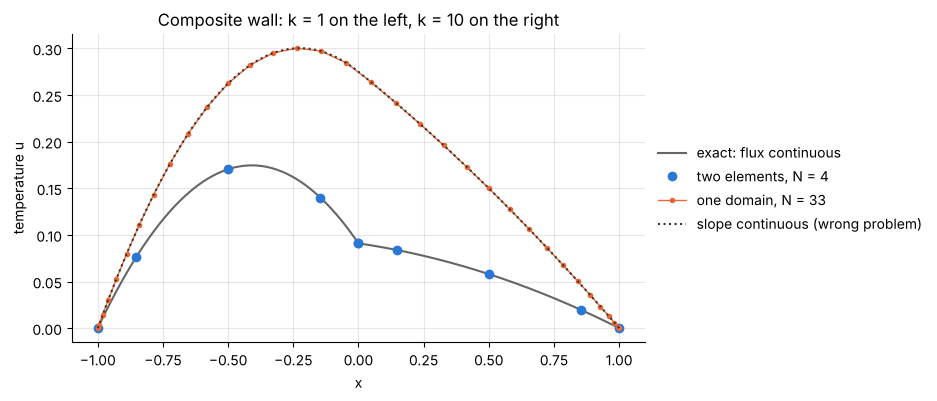

In [4]:
def wall_one_domain(N):
    """One Chebyshev grid on [-1, 1] for k u'' = -1 with k sampled at the grid points (N odd)."""
    D, x = cheb(N)
    L = np.diag(np.where(x > 0, 10.0, 1.0)) @ D @ D
    u = np.zeros(N + 1)
    u[1:-1] = solve(L[1:-1, 1:-1], -np.ones(N - 1))
    return x, u

def continuous_slope(x):
    """Solution of k u'' = -1 with u and u' continuous at x = 0: the wrong interface condition."""
    a, c = -9 / 40, 11 / 40
    return np.where(x < 0, -x**2 / 2 + a * x + c, -x**2 / 20 + a * x + c)

one_N = np.array([17, 33, 65, 129, 257])
to_true, to_other = [], []
print("   N    distance from the true solution    distance from the continuous-slope solution")
for N in one_N:
    x, u = wall_one_domain(N)
    to_true.append(np.abs(u - wall_exact(x)).max())
    to_other.append(np.abs(u - continuous_slope(x)).max())
    print(f"{N:4d}   {to_true[-1]:20.4f}   {to_other[-1]:32.1e}")

fine = np.linspace(-1, 1, 401)
fig, ax = plt.subplots(figsize=(7.4, 4))
ax.plot(fine, wall_exact(fine), color="0.4", lw=1.5, label="exact: flux continuous")
ax.plot(x_two, u_two, "o", ms=6, label="two elements, N = 4")
ax.plot(*wall_one_domain(33), "o-", ms=3, lw=1, label="one domain, N = 33")
ax.plot(fine, continuous_slope(fine), ":", color="0.2", lw=1.5, label="slope continuous (wrong problem)")
ax.set(xlabel="x", ylabel="temperature u", title="Composite wall: k = 1 on the left, k = 10 on the right")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [5]:
# verify: two elements against the hand solution; one domain converges, but to the solution of the wrong problem
assert error_two < 1e-14 and abs(u_two[4] - 1 / 11) < 1e-14 and abs(u_two[5] - 1 / 11) < 1e-14   # both copies of x = 0
assert min(to_true) > 0.15                                              # no convergence to the true solution
assert to_other[-1] < 1e-5 and 1.8 < observed_order(one_N, np.array(to_other)) < 2.2
assert np.abs(continuous_slope(np.array([-1.0, 1.0]))).max() < 1e-12     # the hand solution of (c) satisfies both end conditions

**Answer.** (a) $u = -x^2/2 - 9x/22 + 1/11$ for $x < 0$ and $u = -x^2/20 - 9x/220 + 1/11$ for
$x > 0$. (b) Two elements with $N = 4$ reproduce it to $10^{-16}$, because the solution is a
parabola on each element and the interface row carries the flux condition. (c) The single grid
converges, like $N^{-2}$, to the wrong function: its error against the true solution stays
near 0.18 for every $N$, while its distance from the solution with a continuous slope falls to
$3\times10^{-6}$ at $N = 257$. Sampling a discontinuous coefficient does not tell the method
which quantity is continuous across the jump. That information is an interface condition and
has to be imposed as one. This failure is worse than the one in 16.1: there the single grid
was slow, here it is wrong.

## Exercise 2

**Choosing N without an exact solution.** Reaction and diffusion in a catalyst slab with a
large Thiele modulus $1/\varepsilon$ (notebook 6): $\varepsilon^2 u'' - u = -1$,
$u(\pm1) = 0$, with boundary layers of thickness $\varepsilon$ at both walls. For
$\varepsilon = 0.1, 0.03, 0.01, 0.003$ find the smallest even $N$ for which the last three
Chebyshev coefficients of the computed solution are below $10^{-8}$ times the largest one.
Confirm with the exact solution, written in a form that does not overflow,
$u = 1 - e^{-(1 - |x|)/\varepsilon}\,\dfrac{1 + e^{-2|x|/\varepsilon}}{1 + e^{-2/\varepsilon}}$,
that the true error is then below $10^{-8}$. Fit $N \propto \varepsilon^{-p}$, compare $p$
with 16.3, and use the fit to predict the $N$ needed for $\varepsilon = 0.001$. Check the
prediction.

The same pattern as 16.3: solve, transform the solution to Chebyshev coefficients, and look at
the last three relative to the largest. The solution is even in $x$, so every second
coefficient is zero and a window of three always contains a meaningful one. Increase $N$ in
steps of 2 until the test is passed, and only then look at the exact solution.

    ε       N    true error    N √ε
 0.100     24    6.3e-13    7.59
 0.030     38    1.9e-11    6.58
 0.010     62    8.9e-11    6.20
 0.003    108    4.0e-10    5.92


fit: N proportional to ε^(-0.43)
ε = 0.001: predicted N = 170, found N = 182 with true error 1.0e-09


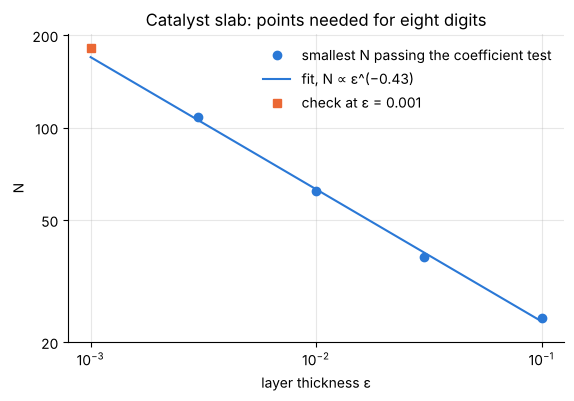

In [6]:
def slab(N, eps):
    D, x = cheb(N)
    L = eps**2 * D @ D - np.eye(N + 1)
    u = np.zeros(N + 1)
    u[1:-1] = solve(L[1:-1, 1:-1], -np.ones(N - 1))
    return x, u

def slab_exact(x, eps):
    return 1 - np.exp(-(1 - np.abs(x)) / eps) * (1 + np.exp(-2 * np.abs(x) / eps)) / (1 + np.exp(-2 / eps))

def smallest_resolved_N(eps, tol=1e-8):
    """Smallest even N whose last three Chebyshev coefficients are below tol times the largest; also the true error."""
    for N in range(4, 600, 2):
        x, u = slab(N, eps)
        a = np.abs(cheb_coeffs(u))
        if a[-3:].max() < tol * a.max():
            return N, np.abs(u - slab_exact(x, eps)).max()

eps_values = np.array([0.1, 0.03, 0.01, 0.003])
found = [smallest_resolved_N(eps) for eps in eps_values]
N_found, true_error = np.array([f[0] for f in found]), np.array([f[1] for f in found])
print("    ε       N    true error    N √ε")
for eps, N, e in zip(eps_values, N_found, true_error):
    print(f"{eps:6.3f}  {N:5d}    {e:.1e}    {N * np.sqrt(eps):.2f}")

slope, intercept = np.polyfit(np.log(eps_values), np.log(N_found), 1)
p = -slope
N_predicted = np.exp(intercept) * 0.001**slope
N_actual, error_actual = smallest_resolved_N(0.001)
print(f"fit: N proportional to ε^(-{p:.2f})")
print(f"ε = 0.001: predicted N = {N_predicted:.0f}, found N = {N_actual} with true error {error_actual:.1e}")

fig, ax = plt.subplots()
ax.loglog(eps_values, N_found, "o", label="smallest N passing the coefficient test")
ax.loglog([0.001, 0.1], np.exp(intercept) * np.array([0.001, 0.1]) ** slope, color="C0", lw=1.5, label=f"fit, N ∝ ε^(−{p:.2f})")
ax.loglog(0.001, N_actual, "s", color="C1", label="check at ε = 0.001")
ax.set(xlabel="layer thickness ε", ylabel="N", yticks=[20, 50, 100, 200], yticklabels=[20, 50, 100, 200],
       title="Catalyst slab: points needed for eight digits")
ax.minorticks_off()
ax.legend(frameon=False, loc="upper right");

In [7]:
# verify: the coefficient test against the exact solution, the exponent against the Chebyshev spacing argument of 16.3
assert np.all(true_error < 1e-8) and error_actual < 1e-8                  # passing the test implies the true error is small
# two points earlier the error is still well above rounding: the test does not pass late
assert all(np.abs(slab(N - 2, eps)[1] - slab_exact(slab(N - 2, eps)[0], eps)).max() > 1e-12 for eps, N in zip(eps_values, N_found))
assert 0.4 < p < 0.55                                                     # near the ε^(-1/2) of 16.3, far from the ε^(-1) of a uniform grid
assert abs(N_predicted / N_actual - 1) < 0.1

**Answer.** The coefficient test asks for $N = 24, 38, 62, 108$ for
$\varepsilon = 0.1, 0.03, 0.01, 0.003$, and in every case the true error is then below
$10^{-8}$ (it is between $10^{-13}$ and $10^{-9}$): the test is safe, and here a little
conservative. The fit gives $p = 0.43$, close to the $\tfrac12$ of 16.3 and nowhere near the
$p = 1$ of a uniform grid. It is below $\tfrac12$ because the product $N\sqrt\varepsilon$ is
still drifting down, from 7.6 to 5.9, over this range. For the same reason the extrapolation
to $\varepsilon = 0.001$ is slightly low: the fit predicts $N = 170$ and the test needs
$N = 182$, 7 per cent more. A boundary layer a thousand times thinner than the slab is
resolved to eight digits with fewer than two hundred points, and without knowing the exact
solution.

## Exercise 3

**A filter in place of the 2/3 rule.** In `burgers`, replace the mask by the smooth filter
$\sigma(k) = \exp\!\big[-36\,(2|k|/N)^{8}\big]$, applied to the solution $\hat u$ at the end
of every time step (and no mask on the nonlinear term). Run the case of 16.4 ($N = 64$,
$\nu = 0.005$, $\Delta t = 0.002$, $t = 4$). Does the run survive? Compare its largest
value of $|u|$ during the run, and its largest and root-mean-square errors at $t = 4$
against the $N = 4096$ reference, with those of the 2/3 rule.

The filter multiplies every Fourier coefficient of the solution once per step. It differs from
1 by less than $10^{-5}$ for $|k| \le 4$ and falls smoothly to $e^{-36} \approx 2\times10^{-16}$, the
rounding level, at the Nyquist wavenumber $|k| = N/2$. Unlike the 2/3 rule it removes no mode
completely, and it does not make the product exact. What it does is damp the highest modes a
little at every step, like a very high-order viscosity.

N = 64      reached t   largest |u|   largest error   rms error  (errors at t = 4)
2/3 rule       4.00       1.256          0.435         0.140
filter         4.00       1.278          0.165         0.043


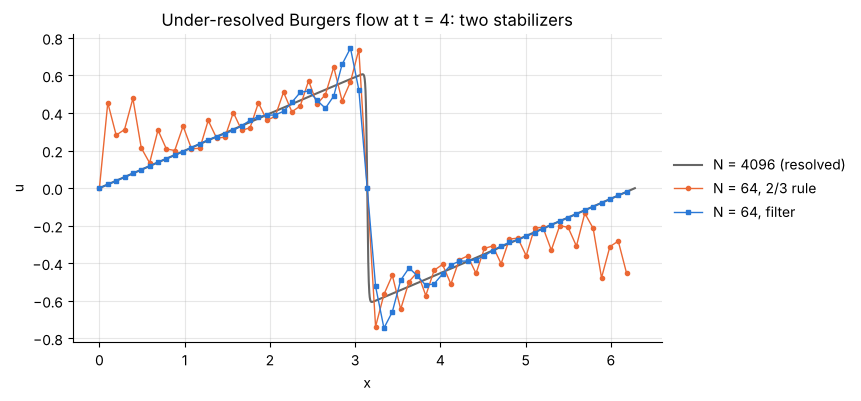

In [8]:
def burgers_filtered(N, nu, t_end, dt):
    """As burgers, without a mask on the nonlinear term and with an exponential filter applied after every step.

    Returns the times, max |u| at each step and the final u.
    """
    x = 2 * np.pi * np.arange(N) / N
    k = np.fft.fftfreq(N, 1 / N)
    ik = 1j * k
    ik[N // 2] = 0
    sigma = np.exp(-36 * (2 * np.abs(k) / N) ** 8)
    E = np.exp(-nu * k**2 * dt / 2)
    E2 = E * E
    nonlinear = lambda v: -fft(np.real(ifft(v)) * np.real(ifft(ik * v)))
    v = fft(np.sin(x))
    times, peak = [0.0], [1.0]
    for n in range(1, round(t_end / dt) + 1):
        k1 = nonlinear(v)
        k2 = nonlinear(E * (v + dt / 2 * k1))
        k3 = nonlinear(E * v + dt / 2 * k2)
        k4 = nonlinear(E2 * v + dt * E * k3)
        v = sigma * (E2 * v + dt / 6 * (E2 * k1 + 2 * E * (k2 + k3) + k4))
        times.append(n * dt)
        peak.append(np.abs(ifft(v)).max())
        if not peak[-1] < 1e3:
            break
    return np.array(times), np.array(peak), np.real(ifft(v))

nu_burgers = 0.005
t_ref, peak_ref, tail_ref, u_ref = burgers(4096, nu_burgers, 4.0, 0.001, dealias=True)       # the resolved reference of 16.4
t_rule, peak_rule, _, u_rule = burgers(64, nu_burgers, 4.0, 0.002, dealias=True)
t_filter, peak_filter, u_filter = burgers_filtered(64, nu_burgers, 4.0, 0.002)
on_coarse_grid = u_ref[::64]
rows = {"2/3 rule": (t_rule, peak_rule, u_rule), "filter": (t_filter, peak_filter, u_filter)}
summary = {}
print("N = 64      reached t   largest |u|   largest error   rms error  (errors at t = 4)")
for name, (t, peak, u) in rows.items():
    summary[name] = (peak.max(), np.abs(u - on_coarse_grid).max(), np.sqrt(np.mean((u - on_coarse_grid) ** 2)))
    print(f"{name:10s}  {t[-1]:7.2f}  {summary[name][0]:10.3f}  {summary[name][1]:13.3f}  {summary[name][2]:12.3f}")

x64, x_ref = 2 * np.pi * np.arange(64) / 64, 2 * np.pi * np.arange(4096) / 4096
fig, ax = plt.subplots(figsize=(7.6, 4))
ax.plot(x_ref, u_ref, color="0.4", lw=1.5, label="N = 4096 (resolved)")
ax.plot(x64, u_rule, "o-", ms=3, lw=1, color="C1", label="N = 64, 2/3 rule")
ax.plot(x64, u_filter, "s-", ms=3, lw=1, color="C0", label="N = 64, filter")
ax.set(xlabel="x", ylabel="u", title="Under-resolved Burgers flow at t = 4: two stabilizers")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

A filter is not free. To see its cost, repeat the comparison for a flow that 64 points can
resolve, $\nu = 0.1$, with an $N = 256$ run as the reference.

In [9]:
smooth_ref = burgers(256, 0.1, 4.0, 0.002, dealias=True)
smooth_rule = np.abs(burgers(64, 0.1, 4.0, 0.002, dealias=True)[3] - smooth_ref[3][::4]).max()
smooth_filter = np.abs(burgers_filtered(64, 0.1, 4.0, 0.002)[2] - smooth_ref[3][::4]).max()
print(f"resolved flow (ν = 0.1), largest error at t = 4: 2/3 rule {smooth_rule:.1e}, filter {smooth_filter:.1e}")

resolved flow (ν = 0.1), largest error at t = 4: 2/3 rule 8.2e-06, filter 1.8e-03


In [10]:
# verify: the reference is resolved and obeys the maximum principle |u| <= 1, which both N = 64 runs violate
k = np.fft.fftfreq(64, 1 / 64)
sigma = np.exp(-36 * (2 * np.abs(k) / 64) ** 8)
assert sigma[0] == 1.0 and abs(sigma[4] - 1) < 1e-5 and sigma[32] < 1e-15           # 1 at low k, rounding level at Nyquist
assert peak_ref.max() < 1 + 1e-9 and tail_ref.max() < 1e-9
assert t_filter[-1] == 4.0 and 1.1 < summary["filter"][0] < 1.5                     # survives, but overshoots
assert summary["filter"][1] < 0.5 * summary["2/3 rule"][1] and summary["filter"][2] < 0.5 * summary["2/3 rule"][2]
assert summary["filter"][1] > 0.05                                                  # and is still far from accurate
assert smooth_rule < 1e-4 < smooth_filter < 1e-2                                    # on a resolved flow the filter is the less accurate

**Answer.** The filtered run survives to $t = 4$. Its largest $|u|$ during the run is 1.28,
against 1.26 with the 2/3 rule, and both violate the bound $|u| \le 1$ of the true solution.
At $t = 4$ the filtered run is closer to the reference: largest error 0.165 against 0.435, and
root-mean-square error 0.043 against 0.140. The plot shows why. With the sharp cut-off of the
2/3 rule nothing damps the modes just below the cut-off, and oscillations fill the whole
interval. The filter removes them smoothly and confines the damage to the neighbourhood of
the front. A factor of about three is still not accuracy: an error of 0.17 in a solution of size 1
is useless for design. And the filter has a price: on a flow that the grid can resolve it
damps modes that the solution needs, and the error is $2\times10^{-3}$ where the 2/3 rule
gives $8\times10^{-6}$. Both are stabilizers. Neither replaces resolution.

## Exercise 4

**Wall shear stress in the square duct.** Differentiating the series of 16.7 gives the
velocity gradient on the wall $x = 1$:
$\dfrac{\partial u}{\partial x}(1, y) = -1 + \dfrac{8}{\pi^2}\displaystyle\sum_{n\ \text{odd}} \dfrac{\cosh(n\pi y/2)}{n^2\cosh(n\pi/2)}$,
which equals $-0.675314$ at the middle of the wall and tends to 0 at the corners. For
$N = 8, 12, 16, 24, 32$ compute the gradient from the Chebyshev solution at the interior
grid points $y_j$ of the wall, by applying the first row of `cheb(N)[0]` in the $x$
direction (remember that $u = 0$ on the walls). Sum the series with 20 000 terms, writing
the ratio of cosh functions with decaying exponentials as in `duct_exact`. Measure the
order of convergence (a) at the middle of the wall and (b) of the largest error along the
wall. Explain the difference, and relate it to 16.7.

The solution array `u[i, j]` holds the interior values, and the wall $x = 1$ is index 0 of the
Chebyshev grid. Because $u = 0$ on the walls, the boundary values contribute nothing and the
gradient at $(1, y_j)$ is row 0 of $D$, without its first and last entries, applied to column
$j$ of the solution. The duct is symmetric in $x$ and $y$, so it does not matter which array
index is called $x$.

   N   gradient at the middle   error there   largest error on the wall   at y =
   8       -0.675472217          1.6e-04            4.7e-03           0.9239
  12       -0.675336241          2.2e-05            2.1e-03           0.9659
  16       -0.675318980          4.5e-06            1.1e-03           0.9808
  24       -0.675314934          4.5e-07            5.1e-04           0.9914
  32       -0.675314568          8.5e-08            2.9e-04           0.9952
observed order: 5.5 at the middle of the wall, 2.0 for the largest error along the wall


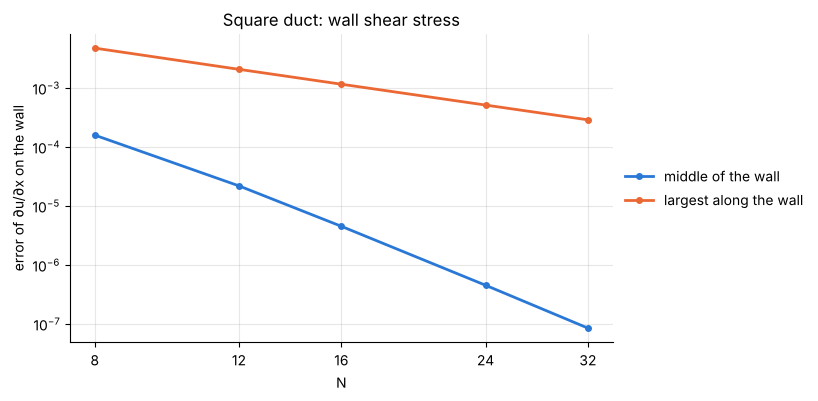

In [11]:
n_odd = np.arange(1, 40001, 2)                                   # 20 000 terms

def wall_gradient_exact(y):
    """Series for ∂u/∂x on the wall x = 1; the ratio of cosh functions is written with decaying exponentials."""
    a = n_odd * np.pi / 2
    ratio = np.exp(np.outer(np.abs(y) - 1, a)) * (1 + np.exp(-2 * np.outer(np.abs(y), a))) / (1 + np.exp(-2 * a))
    return -1 + 8 / np.pi**2 * (ratio / n_odd**2).sum(axis=1)

duct_N = np.array([8, 12, 16, 24, 32])
error_middle, error_wall = [], []
print("   N   gradient at the middle   error there   largest error on the wall   at y =")
for N in duct_N:
    D, x = cheb(N)
    D2, identity = (D @ D)[1:-1, 1:-1], np.eye(N - 1)
    u = solve(np.kron(identity, D2) + np.kron(D2, identity), -np.ones((N - 1) ** 2)).reshape(N - 1, N - 1)
    gradient = D[0, 1:-1] @ u                                    # index 0 is the wall x = +1
    error = np.abs(gradient - wall_gradient_exact(x[1:-1]))
    error_middle.append(error[N // 2 - 1])                       # interior index N/2 − 1 is y = 0
    error_wall.append(error.max())
    print(f"{N:4d}   {gradient[N // 2 - 1]:16.9f}   {error_middle[-1]:14.1e}   {error_wall[-1]:16.1e}   {abs(x[1:-1][np.argmax(error)]):14.4f}")

order_middle, order_wall = observed_order(duct_N, np.array(error_middle)), observed_order(duct_N, np.array(error_wall))
print(f"observed order: {order_middle:.1f} at the middle of the wall, {order_wall:.1f} for the largest error along the wall")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(duct_N, error_middle, "o-", ms=4, label="middle of the wall")
ax.loglog(duct_N, error_wall, "o-", ms=4, label="largest along the wall")
ax.set(xlabel="N", ylabel="error of ∂u/∂x on the wall", xticks=duct_N, xticklabels=duct_N, title="Square duct: wall shear stress")
ax.minorticks_off()
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [12]:
# verify: the series against the value quoted in the exercise and against its limit at the corner
middle_exact = wall_gradient_exact(np.zeros(1))[0]
assert abs(middle_exact + 0.675314) < 1e-6
assert abs(wall_gradient_exact(np.ones(1))[0]) < 2e-5              # −1 + (8/π²) Σ 1/n² = 0: what is left is the truncation of the series
assert error_middle[-1] < 1e-6 and 5 < order_middle < 6.5
assert 1.8 < order_wall < 2.2 and error_wall[-1] > 1e-4

**Answer.** At the middle of the wall the gradient converges like $N^{-5.5}$, and $N = 32$
gives $-0.6753146$, correct to $8\times10^{-8}$. The largest error along the wall falls only
like $N^{-2}$ and is still $3\times10^{-4}$ at $N = 32$. It always sits at the grid point
next to a corner, and that point moves towards the corner as $N$ grows. The exact gradient
there is itself small ($-0.020$ at $N = 32$), so the relative error at that point stays
between 1 and 2 per cent for every $N$. At a fixed position the convergence is much faster:
at $y = 0.981$ the error falls from $1.1\times10^{-3}$ to $6\times10^{-5}$ between $N = 16$
and 32. The cause is the corner singularity of 16.7: the solution contains
$r^2\log r$, so its gradient behaves like $r\log r$ near the corner, with an unbounded
derivative, and a polynomial follows that poorly. The field itself converged like $N^{-4}$
in 16.7, and differentiating at the edge of a Chebyshev grid costs two more powers of $N$.
Far from the corners the singularity is only felt weakly, hence the much higher order at the
middle. So the answer to "has it converged?" depends on the question. The friction factor,
which needs the flow rate, was converged to almost eight digits at $N = 16$. The wall shear
stress next to the corners is good to $3\times10^{-4}$ in absolute terms at $N = 32$, which
is only two digits of its local value.

## Exercise 5

**Find the two mistakes.** The following lines are meant to solve
$u'' = -\pi^2\sin(\pi x)$ on $[0, 1]$ with $u(0) = 0$ and $u'(1) = -\pi$, whose solution is
$u = \sin\pi x$. They run without error and return a smooth curve that is wrong. Find both
mistakes with the checks of 16.9, correct them, and confirm an error below $10^{-10}$.

```python
N = 24
D, xi = cheb(N)
x = (xi + 1) / 2                             # map [-1, 1] to [0, 1]
A = D @ D
b = -np.pi**2 * np.sin(np.pi * x)
A[0, :] = 0; A[0, 0] = 1; b[0] = 0           # u(0) = 0
A[N, :] = D[N, :]; b[N] = -np.pi             # u'(1) = -π
u = np.linalg.solve(A, b)
```

Run the lines as given, then apply two one-line checks from the table of 16.9: print the ends
of the grid, and differentiate a function whose derivative is known.

In [13]:
N = 24
D, xi = cheb(N)
x = (xi + 1) / 2                             # map [-1, 1] to [0, 1]
A = D @ D
b = -np.pi**2 * np.sin(np.pi * x)
A[0, :] = 0; A[0, 0] = 1; b[0] = 0           # u(0) = 0
A[N, :] = D[N, :]; b[N] = -np.pi             # u'(1) = -π
u_wrong = np.linalg.solve(A, b)
print(f"as given: largest error {np.abs(u_wrong - np.sin(np.pi * x)).max():.2f}")
print(f"check 1: x[0] = {x[0]:.0f}, x[N] = {x[N]:.0f}")
print(f"check 2: D applied to x gives {(D @ x)[0]:.2f} (should be 1), D @ D applied to x² gives {(D @ D @ x**2)[0]:.2f} (should be 2)")

as given: largest error 18.85
check 1: x[0] = 1, x[N] = 0
check 2: D applied to x gives 0.50 (should be 1), D @ D applied to x² gives 0.50 (should be 2)


Check 1: the Chebyshev grid runs from right to left, so row 0 is $x = 1$ and row $N$ is
$x = 0$. The two boundary rows are exchanged. Check 2: the interval has length 1, not 2, so
$d/dx = 2\,d/d\xi$. The matrix must be multiplied by 2, which affects both $D^2$ (a factor 4)
and the derivative in the boundary row.

corrected: largest error 9.8e-15


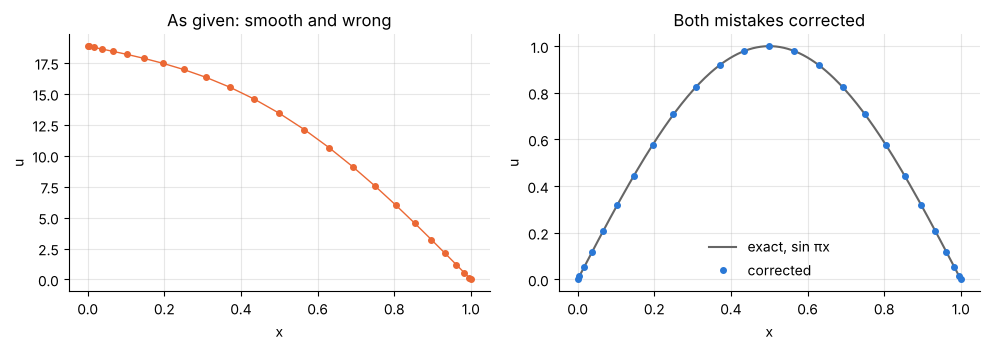

In [14]:
D, xi = cheb(N)
x = (xi + 1) / 2
D = 2 * D                                    # d/dx = 2 d/dξ on an interval of length 1
A = D @ D
b = -np.pi**2 * np.sin(np.pi * x)
A[N, :] = 0; A[N, N] = 1; b[N] = 0           # u(0) = 0: index N is x = 0
A[0, :] = D[0, :]; b[0] = -np.pi             # u'(1) = -π: index 0 is x = 1
u_right = np.linalg.solve(A, b)
error_right = np.abs(u_right - np.sin(np.pi * x)).max()
print(f"corrected: largest error {error_right:.1e}")

fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(x, u_wrong, "o-", ms=4, lw=1, color="C1")
axes[0].set(xlabel="x", ylabel="u", title="As given: smooth and wrong")
axes[1].plot(fine, np.sin(np.pi * fine), color="0.4", lw=1.5, label="exact, sin πx")
axes[1].plot(x, u_right, "o", ms=4, label="corrected")
axes[1].set(xlabel="x", ylabel="u", title="Both mistakes corrected")
axes[1].legend(frameon=False, loc="lower center")
fig.tight_layout()

In [15]:
# verify: the corrected solution against sin πx; each mistake alone is enough to spoil the answer
def attempt(scale, swap_rows):
    D, xi = cheb(N)
    D = scale * D
    A, b = D @ D, -np.pi**2 * np.sin(np.pi * (xi + 1) / 2)
    dirichlet, neumann = (N, 0) if swap_rows else (0, N)
    A[dirichlet, :] = 0; A[dirichlet, dirichlet] = 1; b[dirichlet] = 0
    A[neumann, :] = D[neumann, :]; b[neumann] = -np.pi
    return np.abs(np.linalg.solve(A, b) - np.sin(np.pi * (xi + 1) / 2)).max()

print(f"largest error: as given {attempt(1, False):.2f}, rows corrected only {attempt(1, True):.2f},"
      f" scaling corrected only {attempt(2, False):.2f}, both {attempt(2, True):.1e}")
assert error_right < 1e-10 and attempt(2, True) < 1e-10
assert min(attempt(1, False), attempt(1, True), attempt(2, False)) > 1.0
assert x[0] == 1.0 and x[N] == 0.0 and abs((D @ x)[0] - 1) < 1e-12        # D is now the scaled matrix

largest error: as given 18.85, rows corrected only 6.83, scaling corrected only 6.28, both 9.8e-15


**Answer.** Mistake 1: the boundary rows are exchanged. Row 0 of a Chebyshev grid is the
right end, $x = 1$, so the Dirichlet condition $u(0) = 0$ belongs in row $N$ and the Neumann
condition $u'(1) = -\pi$ in row 0. Mistake 2: the differentiation matrix is not scaled for the
interval $[0, 1]$. Every derivative needs the factor 2, in $D^2$ and in the Neumann row. As
given, the code returns a smooth curve that falls from 18.8 at $x = 0$ to 0 at $x = 1$, an error of 18.85 in a
solution of size 1. Correcting only one of the two mistakes still leaves errors of 6.8 and
6.3. With both corrected the error is $10^{-14}$. Neither mistake produces a warning, a wiggle
or a failed solve. Only the two one-line checks reveal them.